# Improved PINN-CNN: training notebook

This notebook trains an **improved version** of the sparse-physics PINN-CNN and lets you test each improvement separately.
It is self-contained (no previous-model code is imported).

| Improvement | Switch | Idea |
|---|---|---|
| Strided physics | `physics="strided"` | Laplacian on a stride-2 grid with a random offset each step: about 25% of the points, **no top-k / gather**, so the selection overhead of the earlier sparse sampler disappears |
| U-Net density head | `head="unet"` | skip connections from encoder blocks 2 and 3 into the density decoder (aimed at better density-map Dice) |
| Unfreeze last block | `unfreeze_block4=True` | encoder block 4 is fine-tuned with a small learning rate (aimed at classification accuracy) |
| Label smoothing | `label_smoothing=0.1` | softer targets, often better calibration |

**Variants** (pick one in cell 1 with `VARIANT = ...`): `baseline_random`, `strided`, `unet_head`, `unfreeze_block4`, `all_improvements`.
Run each variant with the same seeds and compare against `baseline_random`. Each improvement is a **hypothesis**: keep it only if it
helps on validation and the test-set comparison (with 3+ seeds) shows a real difference.

**Outputs** go to `improved_outputs/<variant>/`: learning curves, ROC/AUC, precision-recall, confusion matrix, classification report,
efficiency numbers and a table row. An optional multi-seed ablation sweep is in the last cell.

**Needs:** `build_masked_loaders.py` in the same folder (data only), and `../Models/pinn_cnn_best.pth` (encoder weights for warm-start).
Not included here: knowledge distillation from the CNN+ConvNeXt hybrid and extra image augmentation (both need changes to the data pipeline).

In [1]:
# 1. Imports, settings and variant selection
import os, sys, time, copy, json, random, resource
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, auc, roc_auc_score,
                             precision_recall_curve, average_precision_score, f1_score)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
ROOT = "/Users/binitdebnath/Desktop/HumBrainSignal/BrainTumor_RGB"
ENC_PATH = "../Models/pinn_cnn_best.pth"          # encoder warm-start (blocks only)
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

cnn_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def sync():
    if device.type == "mps": torch.mps.synchronize()
    elif device.type == "cuda": torch.cuda.synchronize()

COMMON = dict(w_phys=10.0, epochs=15, lr=3e-4, lr_block4=1e-5, frac=0.25)
VARIANTS = {
    "baseline_random": dict(head="plain", physics="random",  unfreeze_block4=False, label_smoothing=0.0),
    "strided":         dict(head="plain", physics="strided", unfreeze_block4=False, label_smoothing=0.0),
    "unet_head":       dict(head="unet",  physics="strided", unfreeze_block4=False, label_smoothing=0.0),
    "unfreeze_block4": dict(head="plain", physics="strided", unfreeze_block4=True,  label_smoothing=0.0),
    "all_improvements": dict(head="unet", physics="strided", unfreeze_block4=True,  label_smoothing=0.1),
}
VARIANT = "all_improvements"      # <- choose one of the keys above, then Run All Cells
SEED = 0

CONFIG = {**COMMON, **VARIANTS[VARIANT], "variant": VARIANT}
OUT_DIR = f"improved_outputs/{VARIANT}"
os.makedirs(OUT_DIR, exist_ok=True)
print("device:", device)
print(CONFIG)

device: mps
{'w_phys': 10.0, 'epochs': 15, 'lr': 0.0003, 'lr_block4': 1e-05, 'frac': 0.25, 'head': 'unet', 'physics': 'strided', 'unfreeze_block4': True, 'label_smoothing': 0.1, 'variant': 'all_improvements'}


In [2]:
# 2. The improved model (self-contained)
def conv_block(cin, cout, p):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout2d(p),
    )


class ImprovedPINNCNN(nn.Module):
    def __init__(self, num_classes=4, head="plain", physics="strided", frac=0.25):
        super().__init__()
        assert head in ("plain", "unet") and physics in ("full", "random", "strided")
        self.head, self.physics, self.frac = head, physics, frac

        # CNN encoder: 224 -> 112 -> 56 -> 28 -> 14
        self.block1 = conv_block(3, 32, 0.10)
        self.block2 = conv_block(32, 64, 0.15)      # output 64 x 56 x 56  (skip)
        self.block3 = conv_block(64, 128, 0.20)     # output 128 x 28 x 28 (skip)
        self.block4 = conv_block(128, 256, 0.25)    # output 256 x 14 x 14

        if head == "unet":                           # decoder with skip connections, 14 -> 28 -> 56
            self.up1 = nn.Conv2d(256, 64, 3, padding=1)
            self.up2 = nn.Conv2d(64 + 128, 32, 3, padding=1)
            self.up3 = nn.Conv2d(32 + 64, 32, 3, padding=1)
            self.out = nn.Conv2d(32, 1, 1)
        else:                                        # plain decoder (as in the earlier models)
            self.density_head = nn.Sequential(
                nn.Conv2d(256, 64, 3, padding=1), nn.ReLU(inplace=True),
                nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(inplace=True),
                nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                nn.Conv2d(32, 1, 1),
            )
        self.log_D = nn.Parameter(torch.tensor(-3.0))
        self.log_rho = nn.Parameter(torch.tensor(0.0))
        self.classifier = nn.Sequential(
            nn.Dropout(0.40), nn.Linear(256 + 3, 128), nn.ReLU(inplace=True),
            nn.Dropout(0.30), nn.Linear(128, num_classes),
        )
        lap = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]).view(1, 1, 3, 3)
        self.register_buffer("lap_kernel", lap)

    def forward(self, x):
        f1 = self.block1(x)
        f2 = self.block2(f1)
        f3 = self.block3(f2)
        f4 = self.block4(f3)
        if self.head == "unet":
            h = F.interpolate(F.relu(self.up1(f4)), scale_factor=2, mode="bilinear", align_corners=False)   # 28 x 28
            h = F.interpolate(F.relu(self.up2(torch.cat([h, f3], 1))), scale_factor=2, mode="bilinear",
                              align_corners=False)                                                          # 56 x 56
            h = F.relu(self.up3(torch.cat([h, f2], 1)))
            u = torch.sigmoid(self.out(h))
        else:
            u = torch.sigmoid(self.density_head(f4))
        pooled = F.adaptive_avg_pool2d(f4, 1).flatten(1)
        u_stats = torch.stack([u.mean((1, 2, 3)), u.amax((1, 2, 3)), (u > 0.5).float().mean((1, 2, 3))], dim=1)
        return self.classifier(torch.cat([pooled, u_stats], dim=1)), u

    # ---------------- physics ----------------
    def dense_residual(self, u):
        D, rho = self.log_D.exp(), self.log_rho.exp()
        res = D * F.conv2d(u, self.lap_kernel, padding=1) + rho * u * (1 - u)
        return res[:, :, 1:-1, 1:-1]                                  # all interior points (54 x 54)

    def strided_residual(self, u, dy, dx):
        """Residual on a stride-2 grid whose origin is (dy, dx). One strided conv: no gather, no top-k."""
        D, rho = self.log_D.exp(), self.log_rho.exp()
        v = u[:, :, dy:, dx:]
        lap = F.conv2d(v, self.lap_kernel, stride=2, padding=1)
        c = v[:, :, ::2, ::2]
        return (D * lap + rho * c * (1 - c))[:, :, 1:-1, 1:-1]       # drop the padding artefacts (26 x 26)

    def random_points(self, u):
        B, _, H, W = u.shape
        interior = (H - 2) * (W - 2)
        n = int(self.frac * interior)
        idx = torch.rand(B, interior, device=u.device).topk(n, dim=1).indices
        return (idx // (W - 2) + 1) * W + (idx % (W - 2) + 1)

    def sparse_residual(self, u, flat_idx):
        W = u.shape[-1]
        D, rho = self.log_D.exp(), self.log_rho.exp()
        uf = u.flatten(1)
        g = lambda i: uf.gather(1, i)
        c = g(flat_idx)
        lap = g(flat_idx - W) + g(flat_idx + W) + g(flat_idx - 1) + g(flat_idx + 1) - 4 * c
        return D * lap + rho * c * (1 - c)

    def physics_loss(self, u):
        if self.physics == "full":
            return self.dense_residual(u).pow(2).mean()
        if self.physics == "strided":
            dy, dx = (int(t) for t in torch.randint(0, 2, (2,)))      # random grid offset each step
            return self.strided_residual(u, dy, dx).pow(2).mean()
        return self.sparse_residual(u, self.random_points(u)).pow(2).mean()

    def n_points(self, H=56, W=56):
        if self.physics == "full":
            return (H - 2) * (W - 2)
        if self.physics == "strided":
            return ((H + 1) // 2 - 2) * ((W + 1) // 2 - 2)            # 26 x 26 = 676
        return int(self.frac * (H - 2) * (W - 2))                     # 729

print("model class defined")

model class defined


In [3]:
# 3. Loss and evaluation helpers
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)


def masked_loss(model, logits, u, y, m, has, w_phys, label_smoothing=0.0, w_seg=1.0):
    # classification on images without masks; BCE + Dice on figshare images with masks; physics term
    kaggle = ~((has > 0) & (y != 2))
    l_cls = (F.cross_entropy(logits[kaggle], y[kaggle], label_smoothing=label_smoothing)
             if kaggle.any() else logits.sum() * 0)
    m56 = F.adaptive_avg_pool2d(m, 56)
    hs = has.view(-1, 1, 1, 1)
    bce = F.binary_cross_entropy(u, m56, reduction="none")
    l_bce = (bce * hs).sum() / (hs.sum() * 56 * 56 + 1e-6)
    tum = (has > 0) & (m56.flatten(1).sum(1) > 0)
    if tum.any():
        inter = (u[tum] * m56[tum]).sum((1, 2, 3))
        l_dice = (1 - (2 * inter + 1) / (u[tum].sum((1, 2, 3)) + m56[tum].sum((1, 2, 3)) + 1)).mean()
    else:
        l_dice = u.new_tensor(0.0)
    l_phys = model.physics_loss(u) if w_phys > 0 else u.new_tensor(0.0)
    return l_cls + w_seg * (l_bce + l_dice) + w_phys * l_phys


@torch.no_grad()
def eval_val(model, loader):
    model.eval(); tot, n, correct = 0.0, 0, 0
    for x, y, *_ in loader:
        logits = model(x.to(device))[0].cpu()
        tot += F.cross_entropy(logits, y, reduction="sum").item()
        n += len(y); correct += (logits.argmax(1) == y).sum().item()
    return tot / n, correct / n


@torch.no_grad()
def dice_score(model, loader):
    model.eval(); d = []
    for x, y, m, _ in loader:
        u = model(x.to(device))[1].cpu()
        p, g = u > 0.5, F.adaptive_avg_pool2d(m, 56) > 0.5
        inter = (p & g).sum((1, 2, 3)).float()
        d.append((2 * inter + 1) / (p.sum((1, 2, 3)) + g.sum((1, 2, 3)) + 1))
    return torch.cat(d).mean().item()


@torch.no_grad()
def get_probs(model, loader):
    model.eval(); P, Y = [], []
    for batch in loader:
        P.append(torch.softmax(model(batch[0].to(device))[0], 1).cpu()); Y.append(batch[1])
    return torch.cat(Y).numpy(), torch.cat(P).numpy()

In [4]:
# 4. Sanity checks (CPU, tiny batch): every head/physics combination, and the strided residual against the dense one
x_chk = torch.randn(2, 3, 224, 224)
for head in ("plain", "unet"):
    for physics in ("full", "random", "strided"):
        m_chk = ImprovedPINNCNN(head=head, physics=physics)
        logits_chk, u_chk = m_chk(x_chk)
        lp = m_chk.physics_loss(u_chk); lp.backward()
        print(f"head={head:5s} physics={physics:8s} | logits {tuple(logits_chk.shape)} u {tuple(u_chk.shape)} "
              f"| points/image {m_chk.n_points():4d} | phys loss finite: {bool(torch.isfinite(lp))}")

m_chk = ImprovedPINNCNN(head="plain", physics="strided")
_, u_chk = m_chk(x_chk)
dense = m_chk.dense_residual(u_chk)                       # u rows/cols 1..54
for dy in (0, 1):
    for dx in (0, 1):
        res = m_chk.strided_residual(u_chk, dy, dx)
        rows = [dy + 2 * (a + 1) - 1 for a in range(res.shape[2])]
        cols = [dx + 2 * (c + 1) - 1 for c in range(res.shape[3])]
        ref = dense[:, :, rows][:, :, :, cols]
        print(f"offset ({dy},{dx}): strided vs dense at the same points, max abs diff = {(res - ref).abs().max().item():.2e} (should be ~1e-8)")
del m_chk

head=plain physics=full     | logits (2, 4) u (2, 1, 56, 56) | points/image 2916 | phys loss finite: True
head=plain physics=random   | logits (2, 4) u (2, 1, 56, 56) | points/image  729 | phys loss finite: True
head=plain physics=strided  | logits (2, 4) u (2, 1, 56, 56) | points/image  676 | phys loss finite: True
head=unet  physics=full     | logits (2, 4) u (2, 1, 56, 56) | points/image 2916 | phys loss finite: True
head=unet  physics=random   | logits (2, 4) u (2, 1, 56, 56) | points/image  729 | phys loss finite: True
head=unet  physics=strided  | logits (2, 4) u (2, 1, 56, 56) | points/image  676 | phys loss finite: True
offset (0,0): strided vs dense at the same points, max abs diff = 2.98e-08 (should be ~1e-8)
offset (0,1): strided vs dense at the same points, max abs diff = 2.98e-08 (should be ~1e-8)
offset (1,0): strided vs dense at the same points, max abs diff = 2.98e-08 (should be ~1e-8)
offset (1,1): strided vs dense at the same points, max abs diff = 2.98e-08 (should be

In [5]:
# 5. Data (build_masked_loaders.py only loads and splits the data, it has no model code)
from build_masked_loaders import build
train_loader, val_loader, mval_loader = build()

test_ds = datasets.ImageFolder(f"{ROOT}/Test", transform=cnn_transform)
assert test_ds.classes == CLASS_NAMES, test_ds.classes
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)
print("test images:", len(test_ds), "| train batches per epoch:", len(train_loader))

figshare pairs: 3064 | per class: [1426  708    0  930]
held-out: 893 | kept after lookalike filter: 2629
class counts [glioma, meningioma, notumor, pituitary]: [1519  907  306 1024]
test images: 363 | train batches per epoch: 118


In [6]:
# 6. Training function and the main run
def train_one(cfg, seed, tag="run", verbose=True):
    set_seed(seed)
    model = ImprovedPINNCNN(head=cfg["head"], physics=cfg["physics"], frac=cfg["frac"]).to(device)
    sd = torch.load(ENC_PATH, map_location=device)
    model.load_state_dict({k: v for k, v in sd.items() if k.startswith("block")}, strict=False)

    unfreeze = cfg["unfreeze_block4"]
    for n, p in model.named_parameters():
        p.requires_grad = (not n.startswith("block")) or (unfreeze and n.startswith("block4"))
    head_params = [p for n, p in model.named_parameters() if not n.startswith("block")]
    groups = [dict(params=head_params, lr=cfg["lr"])]
    if unfreeze:
        groups.append(dict(params=list(model.block4.parameters()), lr=cfg["lr_block4"]))
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    epochs = cfg["epochs"]
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    history, best, best_state = [], -1, None
    for ep in range(epochs):
        model.train()
        for blk in (model.block1, model.block2, model.block3):
            blk.eval()                                   # frozen blocks: keep BatchNorm/Dropout fixed
        if not unfreeze:
            model.block4.eval()
        tot_loss, nb, tot_ce, n_ce, correct = 0.0, 0, 0.0, 0, 0
        sync(); t0 = time.perf_counter()
        for x, y, m, has in train_loader:
            x, y, m, has = x.to(device), y.to(device), m.to(device), has.float().to(device)
            logits, u = model(x)
            loss = masked_loss(model, logits, u, y, m, has, w_phys=cfg["w_phys"],
                               label_smoothing=cfg["label_smoothing"])
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                keep = ~((has > 0) & (y != 2))
                if keep.any():
                    tot_ce += F.cross_entropy(logits[keep], y[keep], reduction="sum").item()
                    n_ce += keep.sum().item()
                    correct += (logits[keep].argmax(1) == y[keep]).sum().item()
            tot_loss += loss.item(); nb += 1
        sched.step(); sync(); epoch_s = time.perf_counter() - t0

        v_ce, v_acc = eval_val(model, val_loader)
        v_dice = dice_score(model, mval_loader)
        history.append(dict(epoch=ep + 1, train_total=tot_loss / nb, train_ce=tot_ce / max(n_ce, 1),
                            train_acc=correct / max(n_ce, 1), val_ce=v_ce, val_acc=v_acc, val_dice=v_dice, epoch_s=epoch_s))
        if verbose:
            print(f"[{tag} s{seed}] epoch {ep+1:2d}/{epochs} | train CE {history[-1]['train_ce']:.3f} acc {history[-1]['train_acc']:.3f}"
                  f" | val CE {v_ce:.3f} acc {v_acc:.3f} Dice {v_dice:.3f} | {epoch_s:.1f}s")
        if v_acc + v_dice > best:                        # model selection on VALIDATION only
            best = v_acc + v_dice
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    torch.save(best_state, f"../Models/improved_{tag}_seed{seed}.pth")
    return model, pd.DataFrame(history)


model, hist = train_one(CONFIG, SEED, tag=VARIANT)
hist.to_csv(f"{OUT_DIR}/history.csv", index=False)
print("D =", round(model.log_D.exp().item(), 4), "| rho =", round(model.log_rho.exp().item(), 4),
      "| physics points per image:", model.n_points())

[all_improvements s0] epoch  1/15 | train CE 0.718 acc 0.755 | val CE 0.473 acc 0.899 Dice 0.244 | 20.0s
[all_improvements s0] epoch  2/15 | train CE 0.366 acc 0.906 | val CE 0.359 acc 0.905 Dice 0.473 | 19.1s
[all_improvements s0] epoch  3/15 | train CE 0.310 acc 0.922 | val CE 0.322 acc 0.911 Dice 0.451 | 19.0s
[all_improvements s0] epoch  4/15 | train CE 0.282 acc 0.927 | val CE 0.309 acc 0.917 Dice 0.508 | 19.1s
[all_improvements s0] epoch  5/15 | train CE 0.297 acc 0.926 | val CE 0.305 acc 0.905 Dice 0.517 | 19.1s
[all_improvements s0] epoch  6/15 | train CE 0.289 acc 0.930 | val CE 0.313 acc 0.911 Dice 0.532 | 19.0s
[all_improvements s0] epoch  7/15 | train CE 0.279 acc 0.933 | val CE 0.308 acc 0.905 Dice 0.544 | 19.3s
[all_improvements s0] epoch  8/15 | train CE 0.262 acc 0.937 | val CE 0.296 acc 0.917 Dice 0.542 | 20.2s
[all_improvements s0] epoch  9/15 | train CE 0.262 acc 0.929 | val CE 0.294 acc 0.917 Dice 0.555 | 22.3s
[all_improvements s0] epoch 10/15 | train CE 0.278 acc 

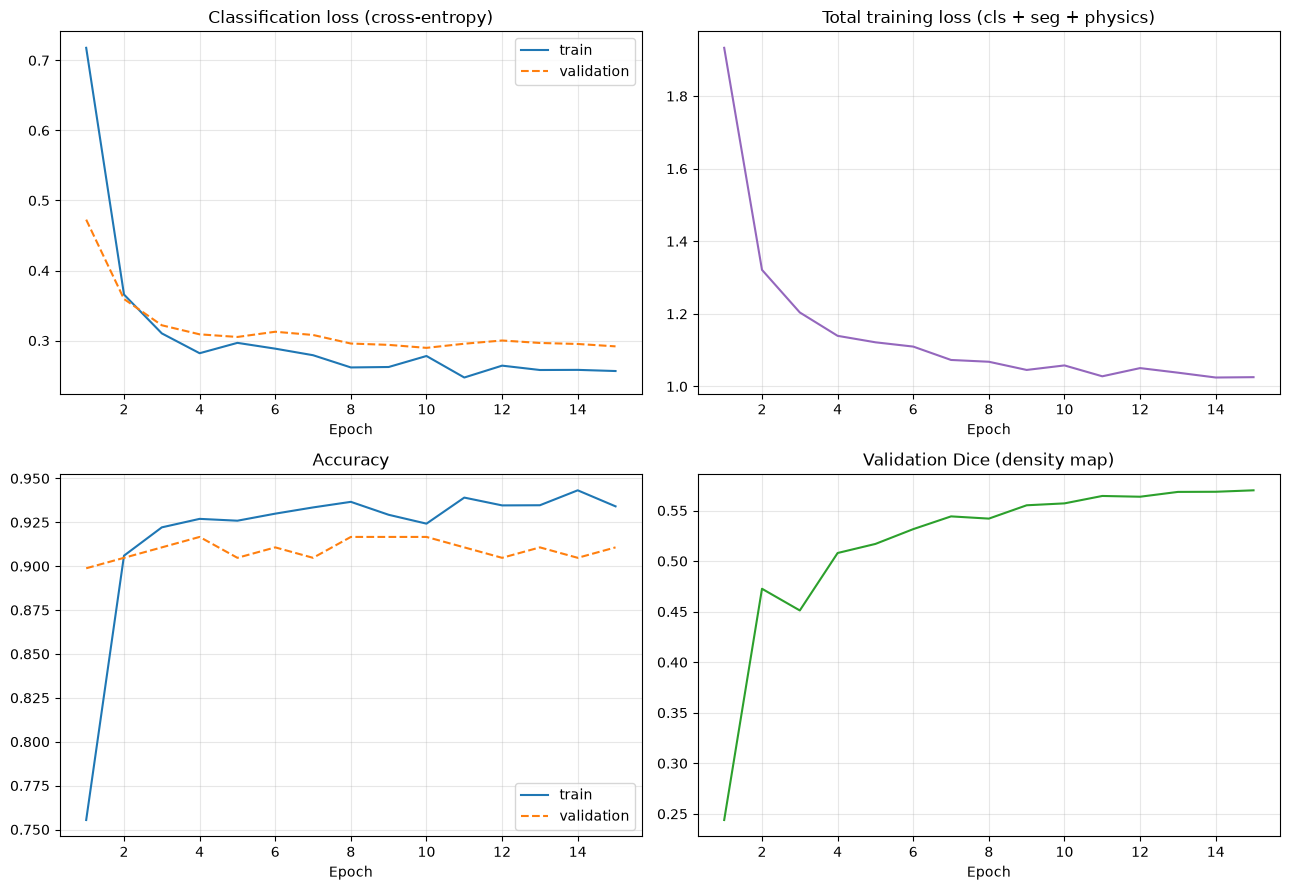

In [7]:
# 7. Learning curves
fig, ax = plt.subplots(2, 2, figsize=(13, 9)); ax = ax.ravel()
ax[0].plot(hist.epoch, hist.train_ce, label="train"); ax[0].plot(hist.epoch, hist.val_ce, "--", label="validation")
ax[0].set_title("Classification loss (cross-entropy)")
ax[1].plot(hist.epoch, hist.train_total, color="tab:purple"); ax[1].set_title("Total training loss (cls + seg + physics)")
ax[2].plot(hist.epoch, hist.train_acc, label="train"); ax[2].plot(hist.epoch, hist.val_acc, "--", label="validation")
ax[2].set_title("Accuracy")
ax[3].plot(hist.epoch, hist.val_dice, color="tab:green"); ax[3].set_title("Validation Dice (density map)")
for a in ax:
    a.set_xlabel("Epoch"); a.grid(alpha=0.3)
for a in (ax[0], ax[2]):
    a.legend()
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/learning_curves.png", dpi=200, bbox_inches="tight"); plt.show()

Improved PINN-CNN [all_improvements] (head=unet, physics=strided, unfreeze_block4=True, label_smoothing=0.1, seed=0)
              precision    recall  f1-score   support

      glioma     0.9231    0.8421    0.8807       114
  meningioma     0.8353    0.8659    0.8503        82
     notumor     0.8861    0.9589    0.9211        73
   pituitary     0.9684    0.9787    0.9735        94

    accuracy                         0.9063       363
   macro avg     0.9032    0.9114    0.9064       363
weighted avg     0.9075    0.9063    0.9060       363

macro ROC-AUC (one-vs-rest): 0.9814
mean average precision: 0.9503



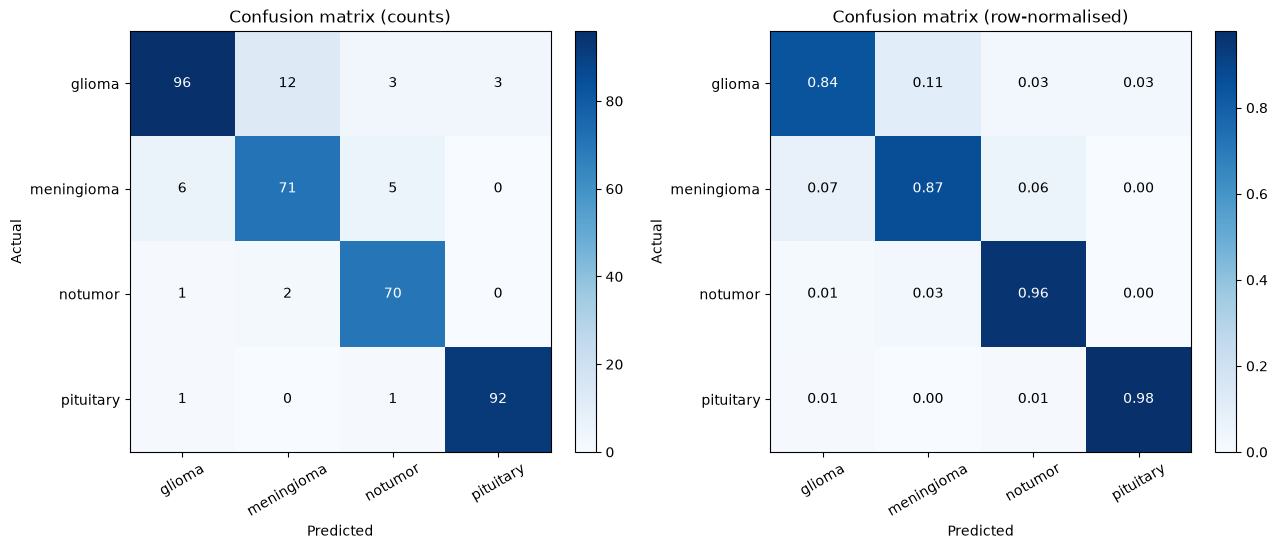

In [8]:
# 8. Test evaluation: classification report and confusion matrix
y_true, probs = get_probs(model, test_loader)
probs = probs.astype(np.float64); probs /= probs.sum(1, keepdims=True)
pred = probs.argmax(1)

report = classification_report(y_true, pred, target_names=CLASS_NAMES, digits=4)
macro_auc = roc_auc_score(y_true, probs, multi_class="ovr", average="macro")
aps = [average_precision_score(y_true == c, probs[:, c]) for c in range(4)]
text = (f"Improved PINN-CNN [{VARIANT}] (head={CONFIG['head']}, physics={CONFIG['physics']}, unfreeze_block4={CONFIG['unfreeze_block4']}, "
        f"label_smoothing={CONFIG['label_smoothing']}, seed={SEED})\n"
        f"{'=' * 70}\n{report}\nmacro ROC-AUC (one-vs-rest): {macro_auc:.4f}\nmean average precision: {np.mean(aps):.4f}\n")
print(text)
open(f"{OUT_DIR}/classification_report.txt", "w").write(text)
np.save(f"{OUT_DIR}/test_probs.npy", probs); np.save(f"{OUT_DIR}/test_labels.npy", y_true)

cm = confusion_matrix(y_true, pred, labels=range(4))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, mat, title, fmt in ((ax[0], cm, "counts", "{:d}"), (ax[1], cmn, "row-normalised", "{:.2f}")):
    im = a.imshow(mat, cmap="Blues")
    a.set_xticks(range(4)); a.set_yticks(range(4))
    a.set_xticklabels(CLASS_NAMES, rotation=30); a.set_yticklabels(CLASS_NAMES)
    for i in range(4):
        for j in range(4):
            v = mat[i, j]
            a.text(j, i, fmt.format(int(v) if title == "counts" else v), ha="center", va="center",
                   color="white" if v > mat.max() * 0.6 else "black")
    a.set_xlabel("Predicted"); a.set_ylabel("Actual"); a.set_title(f"Confusion matrix ({title})")
    fig.colorbar(im, ax=a, fraction=0.046)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=200, bbox_inches="tight"); plt.show()

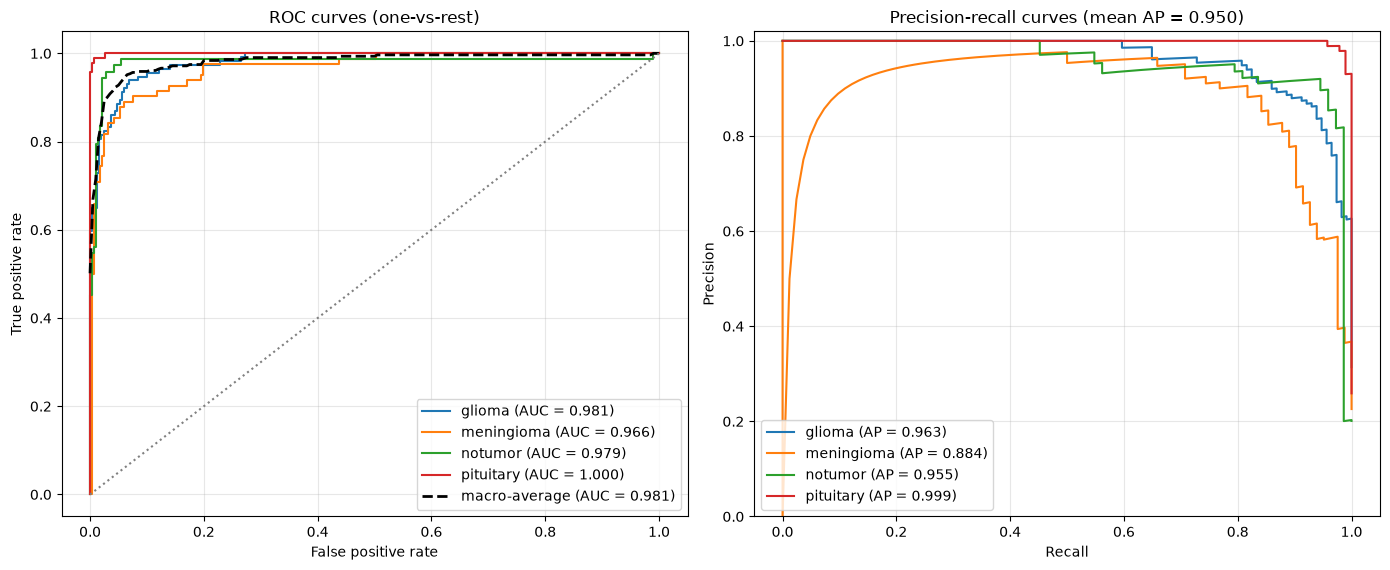

In [9]:
# 9. ROC curves with AUC, and precision-recall curves
fig, ax = plt.subplots(1, 2, figsize=(14, 5.8))
grid = np.linspace(0, 1, 201); tprs = []
for c, cname in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_true == c, probs[:, c])
    ax[0].plot(fpr, tpr, label=f"{cname} (AUC = {auc(fpr, tpr):.3f})")
    tprs.append(np.interp(grid, fpr, tpr))
ax[0].plot(grid, np.mean(tprs, 0), "k--", lw=2, label=f"macro-average (AUC = {auc(grid, np.mean(tprs, 0)):.3f})")
ax[0].plot([0, 1], [0, 1], ":", color="gray")
ax[0].set_title("ROC curves (one-vs-rest)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].legend(loc="lower right"); ax[0].grid(alpha=0.3)

for c, cname in enumerate(CLASS_NAMES):
    prec, rec, _ = precision_recall_curve(y_true == c, probs[:, c])
    ax[1].plot(rec, prec, label=f"{cname} (AP = {aps[c]:.3f})")
ax[1].set_title(f"Precision-recall curves (mean AP = {np.mean(aps):.3f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_ylim(0, 1.02)
ax[1].legend(loc="lower left"); ax[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/roc_pr.png", dpi=200, bbox_inches="tight"); plt.show()

In [10]:
# 10. Efficiency of this model: training time, inference latency, memory, physics cost
def time_ms(fn, n=100, warmup=10):
    for _ in range(warmup): fn()
    sync(); t = time.perf_counter()
    for _ in range(n): fn()
    sync(); return (time.perf_counter() - t) / n * 1000

model.eval()
x1 = torch.randn(1, 3, 224, 224, device=device)
x32 = torch.randn(32, 3, 224, 224, device=device)
def inf1():
    with torch.no_grad(): model(x1)
def inf32():
    with torch.no_grad(): model(x32)
lat1, lat32 = time_ms(inf1), time_ms(inf32, n=30, warmup=5)

# physics term alone (forward + backward) on a real-shaped density map
with torch.no_grad():
    _, u0 = model(x32)
uu = u0.detach().clone().requires_grad_(True)
phys_ms = time_ms(lambda: model.physics_loss(uu).backward(), n=100)

mem = {}
if device.type == "mps":
    mem["mps_driver_alloc_mb"] = torch.mps.driver_allocated_memory() / 2**20
    mem["mps_current_alloc_mb"] = torch.mps.current_allocated_memory() / 2**20
rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
mem["process_peak_rss_mb"] = rss / 2**20 if sys.platform == "darwin" else rss / 2**10

try:
    from torch.utils.flop_counter import FlopCounterMode
    cpu_model = copy.deepcopy(model).cpu().eval()
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        cpu_model(torch.randn(1, 3, 224, 224))
    fwd_gflops = fc.get_total_flops() / 1e9
except Exception as e:
    fwd_gflops = float("nan"); print("FLOP counter unavailable:", e)

n_pts = model.n_points()
eff = dict(
    train_s_per_epoch_mean=hist.epoch_s.mean(), train_s_per_epoch_std=hist.epoch_s.std(),
    train_ms_per_step=hist.epoch_s.mean() / len(train_loader) * 1000,
    inference_latency_ms_bs1=lat1, inference_ms_per_image_bs32=lat32 / 32,
    physics_term_ms_fwd_bwd=phys_ms,
    physics_points_per_image=n_pts, physics_kflops_per_image=n_pts * 12 / 1e3,
    model_forward_gflops=fwd_gflops, **mem)
for k, v in eff.items():
    print(f"{k:32s} {v:.4f}" if isinstance(v, float) else f"{k:32s} {v}")
print("\nNote: memory is measured after training and evaluation in this notebook (the MPS pool only grows).")

train_s_per_epoch_mean           21.5259
train_s_per_epoch_std            2.4835
train_ms_per_step                182.4227
inference_latency_ms_bs1         3.4385
inference_ms_per_image_bs32      2.6673
physics_term_ms_fwd_bwd          0.2636
physics_points_per_image         676
physics_kflops_per_image         8.1120
model_forward_gflops             5.4915
mps_driver_alloc_mb              2323.6094
mps_current_alloc_mb             30.1135
process_peak_rss_mb              1804.4219

Note: memory is measured after training and evaluation in this notebook (the MPS pool only grows).


In [11]:
# 11. Summary table and saved results
best_i = int(hist.val_acc.idxmax())
summary = dict(
    model="ImprovedPINNCNN", variant=VARIANT, head=CONFIG["head"], physics=CONFIG["physics"],
    unfreeze_block4=bool(CONFIG["unfreeze_block4"]), label_smoothing=CONFIG["label_smoothing"],
    w_phys=CONFIG["w_phys"], seed=SEED,
    test_accuracy=float((pred == y_true).mean()), test_macro_f1=float(f1_score(y_true, pred, average="macro")),
    test_macro_auc=float(macro_auc), test_mean_ap=float(np.mean(aps)),
    best_val_acc=float(hist.val_acc.max()), best_epoch=int(hist.epoch[best_i]), final_val_dice=float(hist.val_dice.iloc[-1]),
    **{k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in eff.items()},
)
pd.DataFrame([summary]).T.rename(columns={0: "value"}).to_csv(f"{OUT_DIR}/summary.csv")
json.dump(summary, open(f"{OUT_DIR}/summary.json", "w"), indent=2)
display(pd.DataFrame([summary]).T.rename(columns={0: "value"}))
print("Saved in:", os.path.abspath(OUT_DIR))

,value
model,ImprovedPINNCNN
variant,all_improvements
head,unet
physics,strided
unfreeze_block4,True
label_smoothing,0.1
w_phys,10.0
seed,0
test_accuracy,0.906336
test_macro_f1,0.906408


Saved in: /Users/binitdebnath/Desktop/HybridCNNBrainTumer/Note book/improved_outputs/all_improvements


In [12]:
# 12. Row for the comparison table (Physics points | Peak memory | Physics time | Train/epoch | Accuracy)
mem_mb = eff.get("mps_driver_alloc_mb", eff["process_peak_rss_mb"])     # MPS allocator pool = high-water mark
row = {
    "Model": f"Improved PINN-CNN [{VARIANT}]",
    "Physics points": int(eff["physics_points_per_image"]),
    "Peak memory (MB)": round(float(mem_mb), 1),
    "Physics time (ms)": round(float(eff["physics_term_ms_fwd_bwd"]), 3),
    "Train/epoch (s)": round(float(eff["train_s_per_epoch_mean"]), 2),
    "Accuracy (%)": round(100 * summary["test_accuracy"], 2),
    "Macro AUC": round(summary["test_macro_auc"], 4),
    "Val Dice": round(summary["final_val_dice"], 3),
}
pd.DataFrame([row]).to_csv(f"{OUT_DIR}/table_row.csv", index=False)
print(row)
display(pd.DataFrame([row]))

{'Model': 'Improved PINN-CNN [all_improvements]', 'Physics points': 676, 'Peak memory (MB)': 2323.6, 'Physics time (ms)': 0.264, 'Train/epoch (s)': 21.53, 'Accuracy (%)': 90.63, 'Macro AUC': 0.9814, 'Val Dice': 0.57}


,Model,Physics points,Peak memory (MB),Physics time (ms),Train/epoch (s),Accuracy (%),Macro AUC,Val Dice
0,Improved PINN-CNN [all_improvements],676,2323.6,0.264,21.53,90.63,0.9814,0.57


In [13]:
# 13. OPTIONAL multi-seed ablation sweep (long: roughly 6-10 minutes per run; 5 variants x 3 seeds is about 2 hours)
# Set RUN_SWEEP = True to run it. Keep the Mac plugged in, awake, and other apps closed.
RUN_SWEEP = False
SWEEP_VARIANTS = ["baseline_random", "strided", "unet_head", "unfreeze_block4", "all_improvements"]
SWEEP_SEEDS = [0, 1, 2]

if RUN_SWEEP:
    os.makedirs("improved_outputs", exist_ok=True)
    rows = []
    for v in SWEEP_VARIANTS:
        for s in SWEEP_SEEDS:
            cfg = {**COMMON, **VARIANTS[v], "variant": v}
            m_s, h_s = train_one(cfg, s, tag=v, verbose=False)
            y_s, p_s = get_probs(m_s, test_loader)
            p_s = p_s.astype(np.float64); p_s /= p_s.sum(1, keepdims=True)
            best_row = h_s.loc[(h_s.val_acc + h_s.val_dice).idxmax()]
            rows.append(dict(variant=v, seed=s,
                             test_acc=float((p_s.argmax(1) == y_s).mean()),
                             test_macro_f1=float(f1_score(y_s, p_s.argmax(1), average="macro")),
                             test_macro_auc=float(roc_auc_score(y_s, p_s, multi_class="ovr", average="macro")),
                             val_dice=float(best_row.val_dice), epoch_s=float(h_s.epoch_s.mean())))
            pd.DataFrame(rows).to_csv("improved_outputs/ablation_runs.csv", index=False)     # saved after every run
            print(rows[-1])
    ab = pd.DataFrame(rows)
    print(ab.groupby("variant")[["test_acc", "test_macro_f1", "test_macro_auc", "val_dice", "epoch_s"]]
          .agg(["mean", "std"]).round(4).to_string())
else:
    print("Sweep skipped (RUN_SWEEP = False).")

Sweep skipped (RUN_SWEEP = False).
